# 3. lépés: tesztelés a kérdésekkel
**Bemenet:** `chunks/`, `index/`,`questions.csv`
**Kimenet:** a `results/`

In [1]:
%pip install -q pandas numpy requests openpyxl matplotlib tqdm faiss-cpu

Note: you may need to restart the kernel to use updated packages.


## 1. Beállítások

In [ ]:
import os
from pathlib import Path

PROJECT_DIR = Path(r"C:\path\to\project")

if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(f"Folder not found: {PROJECT_DIR} - set PROJECT_DIR to project folder.")
os.chdir(PROJECT_DIR)
print("Working folder:", Path.cwd())

CHUNKS_DIR = Path("chunks")
INDEX_DIR = Path("index")
QUESTIONS_FILE = Path("questions.csv")
RESULTS_DIR = Path("results")
CACHE_DIR = Path("cache")
LANGS = ["en", "hu"]

K_VALUES = [1, 3, 5, 10]
K_CONTEXT = 5

LLM_BASE_URL = "http://192.168.88.200:1234/v1"
LLM_API_KEY = "lm-studio"

MODELS = {
    "gemma-small": {"family": "gemma", "size": "small", "name": "google/gemma-4-e4b"},
    "gemma-large": {"family": "gemma", "size": "large", "name": "google/gemma-4-31b-qat"},
}
RUN_MODELS = ["gemma-small", "gemma-large"]

TEMPERATURE = 0.0
MAX_TOKENS = 4096
TIMEOUT_S = 1800

for p in [RESULTS_DIR, CACHE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

## 2. Kapcsolat az LM Studio szerverrel

In [10]:
import requests

def list_llm_models():
    r = requests.get(f"{LLM_BASE_URL}/models",
                     headers={"Authorization": f"Bearer {LLM_API_KEY}"}, timeout=30)
    r.raise_for_status()
    return [m["id"] for m in r.json().get("data", [])]

try:
    available = list_llm_models()
    print("Models on the LLM server:")
    for m in available:
        print("  -", m)
    print()
    for key in RUN_MODELS:
        name = MODELS[key]["name"]
        status = "OK" if name in available else "NOT IN THE LIST - fix it in step 1"
        print(f"{key:12s} -> {name}: {status}")
except Exception as e:
    print("Cannot reach the server:", e)
    print("Check LLM_BASE_URL and whether the server is running.")

Models on the LLM server:
  - google/gemma-4-31b-qat
  - google/gemma-4-12b-qat
  - google/gemma-4-26b-a4b-qat
  - text-embedding-nomic-embed-text-v1.5
  - qwen/qwen3.8-27b
  - google/gemma-4-e4b

gemma-small  -> google/gemma-4-e4b: OK
gemma-large  -> google/gemma-4-31b-qat: OK


## 3. A darabok és az index betöltése

In [ ]:
import re, unicodedata

CHAR_MAP = {
    "‘": "'", "’": "'", "‚": "'", "‛": "'",
    "“": '"', "”": '"', "„": '"', "»": '"', "«": '"',
    "–": "-", "—": "-", "−": "-", " ": " ", "­": "",
    "…": "...",
}
_CHAR_RE = re.compile("|".join(map(re.escape, CHAR_MAP)))

def clean_text(text: str) -> str:
    """Unify quotes/dashes, re-join hyphenated line breaks, collapse whitespace (keeps case)."""
    s = unicodedata.normalize("NFC", text)
    s = _CHAR_RE.sub(lambda m: CHAR_MAP[m.group(0)], s)
    s = re.sub(r"(\w)-\s*\n\s*(\w)", r"\1\2", s)
    s = re.sub(r"\s+", " ", s)
    return s.strip()

def normalize(text: str) -> str:
    """For matching: cleaned + lowercase."""
    return clean_text(str(text)).lower()

import requests, time, numpy as np

def embed(texts, model, url, api_key="lm-studio", batch=32, retries=3):
    """Embed texts via the LM Studio /v1/embeddings endpoint. Returns an L2-normalized float32 matrix."""
    vectors = []
    for i in range(0, len(texts), batch):
        part = texts[i:i + batch]
        for attempt in range(retries):
            try:
                r = requests.post(f"{url}/embeddings",
                                  headers={"Authorization": f"Bearer {api_key}"},
                                  json={"model": model, "input": part}, timeout=600)
                r.raise_for_status()
                data = sorted(r.json()["data"], key=lambda d: d["index"])
                vectors += [d["embedding"] for d in data]
                break
            except Exception as e:
                if attempt == retries - 1:
                    raise
                print(f"   error ({e}), retrying...")
                time.sleep(5 * (attempt + 1))
    X = np.asarray(vectors, dtype="float32")
    X /= np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-12, None)
    return X

import hashlib

def fingerprint(texts):
    """Hash of all chunk texts - detects re-chunking without re-indexing."""
    h = hashlib.sha1()
    for t in texts:
        h.update(t.encode("utf-8")); h.update(b"\0")
    return h.hexdigest()

import pandas as pd, json

try:
    import faiss
except ImportError:
    faiss = None
    print("FAISS not installed, using NumPy search (same result).")

INFO = json.loads((INDEX_DIR / "info.json").read_text(encoding="utf-8"))
EMBED_MODEL, EMBED_URL, FORMAT = INFO["model"], INFO["url"], INFO["format"]
CHUNK_INFO = json.loads((CHUNKS_DIR / "info.json").read_text(encoding="utf-8"))

def short_hash(*parts):
    h = hashlib.sha1()
    for p in parts:
        h.update(str(p).encode("utf-8"))
    return h.hexdigest()[:12]

class Index:
    def __init__(self, X):
        self.X = X
        if faiss is not None:
            self.ix = faiss.IndexFlatIP(X.shape[1])
            self.ix.add(X)
    def search(self, q, k):
        k = min(k, len(self.X))
        if faiss is not None:
            s, i = self.ix.search(q[None, :], k)
            return i[0], s[0]
        s = self.X @ q
        i = np.argsort(-s)[:k]
        return i, s[i]

CHUNKS, INDEX = {}, {}
for lang in LANGS:
    df = pd.read_json(CHUNKS_DIR / f"{lang}.jsonl", lines=True)
    if fingerprint(df["text"]) != INFO["langs"][lang]["fingerprint"]:
        raise RuntimeError(f"[{lang}] Chunks changed since indexing - re-run 02_indexing.")
    df["norm"] = df["text"].map(normalize)
    CHUNKS[lang] = df
    INDEX[lang] = Index(np.load(INDEX_DIR / f"{lang}.npy"))
    print(f"[{lang}] {len(df):,} chunks, index: {INDEX[lang].X.shape}")
print("Embedding model:", EMBED_MODEL)

[en] 3,592 chunks, index: (3592, 1024)
[hu] 2,919 chunks, index: (2919, 1024)
Embedding model: text-embedding-multilingual-e5-large-instruct


### Kereső- és ellenőrző segédfüggvények

In [ ]:
def retrieve(question, lang, k=K_CONTEXT):
    q = embed([FORMAT["query"].format(text=question)], EMBED_MODEL, EMBED_URL)[0]
    return INDEX[lang].search(q, k)

def show(question, lang, k=K_CONTEXT, length=300):
    idx, scores = retrieve(question, lang, k)
    df = CHUNKS[lang]
    for rank, (i, s) in enumerate(zip(idx, scores), 1):
        row = df.iloc[i]
        print(f"#{rank}  score={s:.3f}  [{row['id']}]")
        print("   ", row["text"][:length], "...\n")

def find_text(phrase, lang, max_hits=10):
    n = normalize(phrase)
    df = CHUNKS[lang]
    hits = df[df["norm"].str.contains(n, regex=False)]
    print(f"Found in {len(hits)} chunk(s).")
    for _, row in hits.head(max_hits).iterrows():
        pos = row["norm"].find(n)
        print(f"  [{row['id']}] ...{row['text'][max(0, pos-80):pos+len(n)+80]}...")

## 4. A kérdéskészlet

In [ ]:
REQUIRED = ["id", "question_en", "question_hu", "evidence_en", "evidence_hu", "reference_en", "reference_hu"]

if not QUESTIONS_FILE.exists():
    template = pd.DataFrame([{
        "id": "q01", "question_en": "<question in English>", "question_hu": "<question in Hungarian>",
        "evidence_en": "<verbatim English passage>", "evidence_hu": "<verbatim Hungarian passage>",
        "reference_en": "<correct answer>", "reference_hu": "<correct answer>"}], columns=REQUIRED)
    template.to_csv(QUESTIONS_FILE, index=False, sep=";", encoding="utf-8-sig")
    print(f"Template created: {QUESTIONS_FILE}. Fill it in, then re-run this cell.")

def load_questions():
    first = QUESTIONS_FILE.read_text(encoding="utf-8-sig").splitlines()[0]
    sep = ";" if first.count(";") > first.count(",") else "," 
    Q = pd.read_csv(QUESTIONS_FILE, dtype=str, keep_default_na=False, encoding="utf-8-sig", sep=sep)
    missing = [c for c in REQUIRED if c not in Q.columns]
    assert not missing, f"Missing columns: {missing}"
    Q = Q[Q["id"].str.strip() != ""].copy()
    assert Q["id"].is_unique, "ids are not unique."
    for c in ("type", "source"):
        if c not in Q.columns:
            Q[c] = ""
    return Q

def evidence_parts(text):
    return [p.strip() for p in str(text).split("||") if p.strip()]

def gold_chunks(Q):
    gold, not_found = {}, []
    for lang in LANGS:
        df = CHUNKS[lang]
        for _, q in Q.iterrows():
            idx = set()
            for part in evidence_parts(q[f"evidence_{lang}"]):
                hit = set(np.flatnonzero(df["norm"].str.contains(normalize(part), regex=False)))
                if not hit:
                    not_found.append((q["id"], lang, part))
                idx |= hit
            gold[(q["id"], lang)] = idx
    return gold, not_found

Q = load_questions()
GOLD, NOT_FOUND = gold_chunks(Q)

print(f"{len(Q)} question pairs")
problem = False
for _, q in Q.iterrows():
    for lang in LANGS:
        if not evidence_parts(q[f"evidence_{lang}"]):
            problem = True
            print(f"  MISSING {q['id']} [{lang}]: evidence_{lang} is empty.")
for qid, lang, part in NOT_FOUND:
    problem = True
    print(f"  ERROR   {qid} [{lang}]: evidence not found in any chunk - copy it exactly from the text: {part[:60]}")
if not problem:
    print("Evidence for every question found in both corpora.")
print("Gold chunks per question:", {f"{i}/{l}": len(v) for (i, l), v in GOLD.items()})

15 question pairs
Evidence for every question found in both corpora.
Gold chunks per question: {'q01/en': 2, 'q02/en': 4, 'q03/en': 2, 'q04/en': 2, 'q05/en': 2, 'q06/en': 3, 'q07/en': 1, 'q08/en': 2, 'q09/en': 2, 'q10/en': 4, 'q11/en': 1, 'q12/en': 3, 'q13/en': 2, 'q14/en': 1, 'q15/en': 1, 'q01/hu': 4, 'q02/hu': 2, 'q03/hu': 2, 'q04/hu': 4, 'q05/hu': 2, 'q06/hu': 4, 'q07/hu': 1, 'q08/hu': 2, 'q09/hu': 2, 'q10/hu': 2, 'q11/hu': 1, 'q12/hu': 2, 'q13/hu': 3, 'q14/hu': 1, 'q15/hu': 1}


## 5. A visszakeresés mérése

In [ ]:
K_MAX = max(K_VALUES)
RET_CACHE = CACHE_DIR / f"retrieved_{short_hash(EMBED_MODEL, json.dumps(FORMAT), *[INFO['langs'][l]['fingerprint'] for l in LANGS])}.json"
ret_cache = json.loads(RET_CACHE.read_text(encoding="utf-8")) if RET_CACHE.exists() else {}
RETRIEVED = {}
rows = []
for _, q in Q.iterrows():
    for lang in LANGS:
        ckey = f"{lang}|{q[f'question_{lang}']}"
        if ckey in ret_cache and len(ret_cache[ckey]) >= K_MAX:
            idx = ret_cache[ckey][:K_MAX]
        else:
            idx, _ = retrieve(q[f"question_{lang}"], lang, K_MAX)
            idx = [int(i) for i in idx]
            ret_cache[ckey] = idx
        RETRIEVED[(q["id"], lang)] = list(idx)
        gold = GOLD[(q["id"], lang)]
        if not gold:
            continue
        rank = next((r for r, i in enumerate(idx, 1) if i in gold), None)
        row = {"id": q["id"], "lang": lang, "rank": rank, "rr": 1 / rank if rank else 0.0}
        for k in K_VALUES:
            row[f"hit@{k}"] = int(rank is not None and rank <= k)
        rows.append(row)

_ = RET_CACHE.write_text(json.dumps(ret_cache, ensure_ascii=False), encoding="utf-8")
RET = pd.DataFrame(rows, columns=["id", "lang", "rank", "rr"] + [f"hit@{k}" for k in K_VALUES])
ret_summary = RET.groupby("lang")[[f"hit@{k}" for k in K_VALUES] + ["rr"]].mean()
ret_summary.columns = [f"Recall@{k}" for k in K_VALUES] + [f"MRR@{K_MAX}"]
ret_summary["n"] = RET.groupby("lang").size()
RET.to_csv(RESULTS_DIR / "retrieval_per_question.csv", index=False)
ret_summary.to_csv(RESULTS_DIR / "retrieval_summary.csv")
ret_summary.round(3)

,Recall@1,Recall@3,Recall@5,Recall@10,MRR@10,n
lang,,,,,,
en,0.333,0.533,0.600,0.733,0.466,15
hu,0.267,0.400,0.467,0.533,0.358,15


In [ ]:
h = f"hit@{K_CONTEXT}"
pairs = RET.pivot(index="id", columns="lang", values=["rank", h])
pairs.columns = [f"{a}_{b}" for a, b in pairs.columns]
diff = pairs[pairs.get(f"{h}_en") != pairs.get(f"{h}_hu")] if len(pairs) else pairs
print(f"{len(diff)} question pair(s) where {h} differs between languages:")
diff.merge(Q.set_index("id")[["question_en", "question_hu"]], left_index=True, right_index=True)

## 6. Promptok és a modellhívás

In [ ]:
PROMPTS = {
    ("rag", "en"): (
        "Answer the question using ONLY the numbered passages below from the book.\n"
        "If the passages do not contain the answer, reply with exactly: NOT_IN_CONTEXT\n"
        "Answer in English, briefly (1-3 sentences), and cite the passage numbers in brackets, e.g. [2].\n\n"
        "Passages:\n{context}\n\nQuestion: {question}\nAnswer:"
    ),
    ("rag", "hu"): (
        "Válaszolj a kérdésre KIZÁRÓLAG az alábbi, a könyvből származó számozott részletek alapján.\n"
        "Ha a részletek nem tartalmazzák a választ, pontosan ezt írd: NOT_IN_CONTEXT\n"
        "Magyarul válaszolj, röviden (1-3 mondat), és szögletes zárójelben add meg a részlet számát, pl. [2].\n\n"
        "Részletek:\n{context}\n\nKérdés: {question}\nVálasz:"
    ),
    ("base", "en"): (
        "Answer the following question about the book series briefly (1-3 sentences), in English.\n"
        "If you do not know the answer, reply with exactly: UNKNOWN\n\n"
        "Question: {question}\nAnswer:"
    ),
    ("base", "hu"): (
        "Válaszolj röviden (1-3 mondat), magyarul az alábbi, a könyvsorozatra vonatkozó kérdésre.\n"
        "Ha nem tudod a választ, pontosan ezt írd: UNKNOWN\n\n"
        "Kérdés: {question}\nVálasz:"
    ),
}

def build_context(idx, lang):
    df = CHUNKS[lang]
    return "\n\n".join(f"[{r}] {df.iloc[i]['text']}" for r, i in enumerate(idx, 1))

def build_prompt(mode, lang, question, idx=None):
    if mode == "rag":
        return PROMPTS[(mode, lang)].format(context=build_context(idx, lang), question=question)
    return PROMPTS[(mode, lang)].format(question=question)

_THINK = re.compile(r"<think>.*?</think>", flags=re.S)

def chat(model_name, prompt, retries=3):
    for attempt in range(retries):
        try:
            r = requests.post(
                f"{LLM_BASE_URL}/chat/completions",
                headers={"Authorization": f"Bearer {LLM_API_KEY}"},
                json={"model": model_name,
                      "messages": [{"role": "user", "content": prompt}],
                      "temperature": TEMPERATURE, "max_tokens": MAX_TOKENS},
                timeout=TIMEOUT_S)
            r.raise_for_status()
            data = r.json()
            choice = data["choices"][0]
            text = choice["message"].get("content") or ""
            text = _THINK.sub("", text)
            text = text.split("</think>")[-1]
            finish = choice.get("finish_reason")
            tokens = (data.get("usage") or {}).get("completion_tokens")
            return text.strip(), finish, tokens
        except Exception as e:
            if attempt == retries - 1:
                raise
            print(f"   error ({e}), retrying...")
            time.sleep(5 * (attempt + 1))

GEN_FILE = CACHE_DIR / "generations.jsonl"

def load_generations():
    d = {}
    if GEN_FILE.exists():
        for line in GEN_FILE.read_text(encoding="utf-8").splitlines():
            if line.strip():
                r = json.loads(line)
                d[r["key"]] = r
    return d

## 7. A generálás futtatása

In [ ]:
from tqdm.auto import tqdm

TRIAL_N = None

GEN = load_generations()
run_q = Q if TRIAL_N is None else Q.head(TRIAL_N)

with open(GEN_FILE, "a", encoding="utf-8") as out:
    for mkey in RUN_MODELS:
        m = MODELS[mkey]
        jobs = [(q, mode, lang) for _, q in run_q.iterrows() for mode in ("rag", "base") for lang in LANGS]
        for q, mode, lang in tqdm(jobs, desc=mkey):
            idx = RETRIEVED[(q["id"], lang)][:K_CONTEXT] if mode == "rag" else None
            prompt = build_prompt(mode, lang, q[f"question_{lang}"], idx)
            key = short_hash(m["name"], mode, lang, q["id"], prompt, TEMPERATURE, MAX_TOKENS)
            if key in GEN:
                continue
            t0 = time.time()
            answer, finish, tokens = chat(m["name"], prompt)
            rec = {"key": key, "id": q["id"], "model": mkey, "model_name": m["name"],
                   "family": m["family"], "size": m["size"], "mode": mode, "lang": lang,
                   "answer": answer, "finish_reason": finish, "completion_tokens": tokens,
                   "max_tokens": MAX_TOKENS, "seconds": round(time.time() - t0, 2),
                   "context_idx": [int(i) for i in idx] if idx is not None else None}
            GEN[key] = rec
            out.write(json.dumps(rec, ensure_ascii=False) + "\n")
            out.flush()
current = [r for r in GEN.values() if r.get("max_tokens") == MAX_TOKENS and r["model"] in RUN_MODELS]
cut = [r for r in current if r.get("finish_reason") == "length"]
empty = [r for r in current if not r["answer"].strip()]
print(f"Done. Answers with the current settings: {len(current)}")
print(f"  cut off by MAX_TOKENS: {len(cut)}   empty: {len(empty)}")
if cut or empty:
    print("  -> raise MAX_TOKENS in step 1 and re-run steps 1 and 7 (only the affected settings are regenerated).")

C:\Users\<user>\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
gemma-large: 100%|██████████| 60/60 [2:23:17<00:00, 143.29s/it]  

Done. Answers with the current settings: 136
  cut off by MAX_TOKENS: 2   empty: 2
  -> raise MAX_TOKENS in step 1 and re-run steps 1 and 7 (only the affected settings are regenerated).


## 8. A válaszok áttekintése

In [17]:
REFUSAL_RE = re.compile(r"NOT_IN_CONTEXT|UNKNOWN", flags=re.I)

def build_results():
    E = pd.DataFrame(list(load_generations().values()))
    E = E[E["model"].isin(RUN_MODELS)]
    # Only answers generated with the current MAX_TOKENS (older runs with other settings are ignored).
    E = E[E.get("max_tokens", pd.Series(index=E.index, dtype=float)) == MAX_TOKENS]
    # If a setting changed, old and new answers may coexist: keep the latest.
    E = E.drop_duplicates(subset=["id", "model", "mode", "lang"], keep="last")
    E = E.merge(Q, on="id", how="inner")
    E["refused"] = E["answer"].str.contains(REFUSAL_RE)
    # hit = was a gold chunk among the chunks actually given to the model?
    E["hit"] = [float(any(int(c) in GOLD.get((i, lang), set()) for c in ctx)) if mode == "rag" and isinstance(ctx, list) else np.nan
                for i, lang, mode, ctx in zip(E["id"], E["lang"], E["mode"], E["context_idx"])]
    return E

E = build_results()
print(len(E), "answers")
E[["id", "model", "mode", "lang", "answer", "refused", "hit"]].head(12)

120 answers


,id,model,mode,lang,answer,refused,hit
0,q01,gemma-small,base,en,UNKNOWN,True,NaN
1,q01,gemma-small,base,hu,UNKNOWN,True,NaN
2,q02,gemma-small,base,en,UNKNOWN,True,NaN
3,q02,gemma-small,base,hu,UNKNOWN,True,NaN
4,q03,gemma-small,base,en,Beorn was a man with the ability to shapeshift...,False,NaN
5,q03,gemma-small,base,hu,"Beorn egy ember volt, aki a természet és az ál...",False,NaN
6,q01,gemma-large,base,en,"The last riddle Bilbo asked Gollum was, ""What ...",False,NaN
7,q01,gemma-large,base,hu,Bilbó utolsó kérdése az volt: „Mit van a zsebe...,False,NaN
8,q02,gemma-large,base,en,Gandalf discovered the moon-letters on Thrór's...,False,NaN
9,q02,gemma-large,base,hu,Gandalf fedezte fel a Hold-rúnákat Bilbo házáb...,False,NaN


## 9. Kézi értékelés

In [18]:
MANUAL_FILE = RESULTS_DIR / "manual_scores.xlsx"
KEY_COLS = ["id", "model", "mode", "lang"]
MANUAL_COLS = ["manual_correct", "manual_faithful"]

def export_manual(E):
    X = E[KEY_COLS + ["type", "source", "question_en", "question_hu", "reference_en", "reference_hu",
                      "answer", "refused", "hit"]].copy()
    X["question"] = np.where(X["lang"] == "en", X["question_en"], X["question_hu"])
    X["reference"] = np.where(X["lang"] == "en", X["reference_en"], X["reference_hu"])
    X = X.drop(columns=["question_en", "question_hu", "reference_en", "reference_hu"])
    X = X[KEY_COLS + ["question", "reference", "answer", "refused", "hit", "type", "source"]]
    if MANUAL_FILE.exists():
        old = pd.read_excel(MANUAL_FILE)[KEY_COLS + ["answer"] + MANUAL_COLS]
        old["answer"] = old["answer"].fillna("").astype(str)
        X["answer"] = X["answer"].fillna("").astype(str)
        X = X.merge(old, on=KEY_COLS + ["answer"], how="left")
    else:
        for c in MANUAL_COLS:
            X[c] = np.nan
    X = X.sort_values(["id", "lang", "mode", "model"])
    X.to_excel(MANUAL_FILE, index=False)
    done = X["manual_correct"].notna().sum()
    print(f"Written: {MANUAL_FILE} ({len(X)} rows, {done} already scored)")

export_manual(E)

Written: results\manual_scores.xlsx (120 rows, 0 already scored)


In [20]:
def final_table(E):
    if MANUAL_FILE.exists():
        manual = pd.read_excel(MANUAL_FILE)[KEY_COLS + ["answer"] + MANUAL_COLS]
        manual["answer"] = manual["answer"].fillna("").astype(str)
        E = E.drop(columns=[c for c in MANUAL_COLS if c in E.columns])
        E["answer"] = E["answer"].fillna("").astype(str)
        E = E.merge(manual, on=KEY_COLS + ["answer"], how="left")
    else:
        for c in MANUAL_COLS:
            E[c] = np.nan
    E["correct"] = pd.to_numeric(E["manual_correct"], errors="coerce")
    E["faithful"] = pd.to_numeric(E["manual_faithful"], errors="coerce")
    return E

E = final_table(build_results())
HAS_SCORES = E["correct"].notna().any()
missing = E["correct"].isna().sum()
print(f"Scored: {E['correct'].notna().sum()} / {len(E)}")
if missing:
    print(f"WARNING: {missing} answer(s) not scored yet - they are left out of the results below.")

Scored: 120 / 120


## 10. Eredmények

In [21]:
if not HAS_SCORES:
    print("No manual scores yet - fill in results/manual_scores.xlsx, then re-run from step 9.")
else:
    S_ = E[E["correct"].notna()]
    T = S_.groupby(["family", "size", "lang", "mode"]).agg(
        accuracy=("correct", "mean"), faithfulness=("faithful", "mean"),
        refusal_rate=("refused", "mean"), n=("id", "nunique"))
    T.to_csv(RESULTS_DIR / "summary.csv")
    display(T.round(3))

    gain = T["accuracy"].unstack("mode")
    if {"rag", "base"} <= set(gain.columns):
        gain["rag_gain"] = gain["rag"] - gain["base"]
    display(gain.round(3))

accuracy  faithfulness  refusal_rate   n
family size  lang mode                                          
gemma  large en   base     0.933           NaN         0.000  15
                  rag      0.633           NaN         0.200  15
             hu   base     0.600           NaN         0.200  15
                  rag      0.567           NaN         0.267  15
       small en   base     0.167           NaN         0.600  15
                  rag      0.433           NaN         0.467  15
             hu   base     0.100           NaN         0.600  15
                  rag      0.267           NaN         0.400  15

mode                base    rag  rag_gain
family size  lang                        
gemma  large en    0.933  0.633    -0.300
             hu    0.600  0.567    -0.033
       small en    0.167  0.433     0.267
             hu    0.100  0.267     0.167

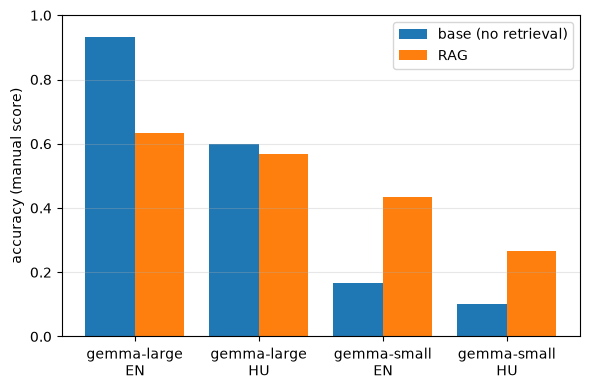

In [22]:
import matplotlib.pyplot as plt
if not HAS_SCORES:
    print("No manual scores yet - fill in results/manual_scores.xlsx, then re-run from step 9.")
else:

    P = T["accuracy"].unstack(["mode"]).reset_index()
    P["label"] = P["family"] + "-" + P["size"] + "\n" + P["lang"].str.upper()
    x = np.arange(len(P))
    fig, ax = plt.subplots(figsize=(max(6, 1.1 * len(P)), 4))
    ax.bar(x - 0.2, P["base"] if "base" in P else 0, 0.4, label="base (no retrieval)")
    ax.bar(x + 0.2, P["rag"] if "rag" in P else 0, 0.4, label="RAG")
    ax.set_xticks(x, P["label"])
    ax.set_ylim(0, 1)
    ax.set_ylabel("accuracy (manual score)")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "accuracy.png", dpi=150)
    plt.show()

## 11. Honnan erednek az angol–magyar eltérések?

| eset a gyengébb nyelven | besorolás |
|---|---|
| a keresés nem hozta be a gold darabot (`hit = 0`) | **retrieval** (visszakeresés) |
| a keresés behozta (`hit = 1`), mégis rossz a válasz | **generation** (generálás) |

In [23]:
if not HAS_SCORES:
    print("No manual scores yet - fill in results/manual_scores.xlsx, then re-run from step 9.")
else:

    R = E[(E["mode"] == "rag") & E["correct"].notna()]
    W = R.pivot_table(index=["model", "id"], columns="lang", values=["correct", "hit"])
    W.columns = [f"{a}_{b}" for a, b in W.columns]
    W = W.reset_index().dropna(subset=["correct_en", "correct_hu"])

    def classify(r):
        en_ok, hu_ok = r["correct_en"] >= 0.5, r["correct_hu"] >= 0.5
        if en_ok == hu_ok:
            return "same"
        weak, strong = ("hu", "en") if en_ok else ("en", "hu")
        if pd.isna(r.get(f"hit_{weak}")):
            return f"only {strong.upper()} correct - (no gold chunk for {weak.upper()})"
        cause = "retrieval" if r[f"hit_{weak}"] == 0 else "generation"
        if r.get(f"hit_{strong}") == 0:
            cause += " (better language answered from model knowledge)"
        return f"only {strong.upper()} correct - {cause}"

    W["case"] = W.apply(classify, axis=1)
    W.to_csv(RESULTS_DIR / "en_hu_pairs.csv", index=False)
    display(pd.crosstab(W["model"], W["case"]))


case,only EN correct - retrieval,only EN correct - retrieval (better language answered from model knowledge),only HU correct - retrieval,only HU correct - retrieval (better language answered from model knowledge),same
model,,,,,
gemma-large,2,1,1,1,10
gemma-small,1,2,0,0,12


## 12. Futtatási környezet

- beágyazás (`192.168.88.10`): Intel Core i5-11400, 32 GB RAM, Intel UHD 730 (Vulkan);
- nyelvi modell (`192.168.88.200`): AMD Ryzen 7 7800X3D, 64 GB RAM, NVIDIA RTX 5080 16 GB (CUDA).

In [25]:
import platform, sys

environment = {
    "python": sys.version.split()[0], "os": platform.platform(),
    "chunking": CHUNK_INFO, "embedding": {"model": EMBED_MODEL, "format": FORMAT, "url": EMBED_URL},
    "k_context": K_CONTEXT, "temperature": TEMPERATURE, "max_tokens": MAX_TOKENS,
    "llm_url": LLM_BASE_URL, "models": {k: MODELS[k] for k in RUN_MODELS},
    "n_chunks": {lang: len(CHUNKS[lang]) for lang in LANGS},
    "n_question_pairs": int(len(Q)),
}
try:
    G = pd.DataFrame(list(load_generations().values()))
    environment["mean_answer_seconds"] = G.groupby("model")["seconds"].mean().round(1).to_dict()
except Exception:
    pass
_ = (RESULTS_DIR / "settings.json").write_text(json.dumps(environment, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(environment, ensure_ascii=False, indent=2))

{
  "python": "3.14.7",
  "os": "Windows-11-10.0.26300-SP0",
  "chunking": {
    "method": "fixed size + overlap (words)",
    "chunk_words": 200,
    "overlap_words": 40,
    "books": {
      "en": [
        "1_Hobbit_or_there_and_back_again",
        "2_The_Fellowship_Of_The_Ring",
        "3_The_Two_Towers",
        "4_The_Return_Of_The_King"
      ],
      "hu": [
        "1_a_hobbit",
        "2_a_gyuruk_ura_a_gyuru_szovetsege",
        "3_a_gyuruk_ura_a_kiraly_visszater",
        "4_a_gyuruk_ura_a_ket_torony"
      ]
    }
  },
  "embedding": {
    "model": "text-embedding-multilingual-e5-large-instruct",
    "format": {
      "query": "Instruct: Given a question about a novel, retrieve passages from the novel that answer the question\nQuery: {text}",
      "passage": "{text}"
    },
    "url": "http://192.168.88.10:1234/v1"
  },
  "k_context": 5,
  "temperature": 0.0,
  "max_tokens": 4096,
  "llm_url": "http://192.168.88.200:1234/v1",
  "models": {
    "gemma-small": {
      "fa